In [1]:
import pandas as pd  
import torch
from torch.utils.data import TensorDataset, DataLoader 
from torch import nn,optim
import matplotlib.pyplot as plt 
import numpy as np  
import random

### 이진 분류 실습 문제 1

## Iris Dataset
: 붓꽃의 꽃받침과 꽃잎의 측정값을 이용해 Setosa와 Versicolor 두 품종을 구분하는 이진 분류 모델 구현.

- 전체 데이터: 150개
- 이번 실습에서 사용할 데이터: 100개
- 입력 특징: 4개
- 정답: 꽃 품종 (Setosa 또는 Versicolor)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `sepal_length` | 꽃받침 길이 | 꽃받침의 길이, cm |
| `sepal_width` | 꽃받침 너비 | 꽃받침의 너비, cm |
| `petal_length` | 꽃잎 길이 | 꽃잎의 길이, cm |
| `petal_width` | 꽃잎 너비 | 꽃잎의 너비, cm |
| `species` | 꽃 품종 | `setosa`, `versicolor`, `virginica` |


#### Step1. 데이터 불러오기 및 전처리

**실습 조건**
- `setosa`와 `versicolor` 두 품종만 사용하고 `virginica`는 제외한다.
- `setosa`는 클래스 0, `versicolor`는 클래스 1로 변환한다.
- 4개의 측정값을 입력값(X), 품종 레이블을 정답(y)으로 사용한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 학습 데이터의 평균과 표준편차를 이용해 입력 특징을 표준화한다.

In [30]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
columns = ['sepal_length','sepal_width','petal_length','petal_width','species']
df = pd.read_csv(url,names=columns)

# Setosa와 Versicolor만 선택
df = df[df["species"].isin(["setosa", "versicolor"])].copy()
print(df)

    sepal_length sepal_width petal_length petal_width     species
1            5.1         3.5          1.4         0.2      setosa
2            4.9         3.0          1.4         0.2      setosa
3            4.7         3.2          1.3         0.2      setosa
4            4.6         3.1          1.5         0.2      setosa
5            5.0         3.6          1.4         0.2      setosa
..           ...         ...          ...         ...         ...
96           5.7         3.0          4.2         1.2  versicolor
97           5.7         2.9          4.2         1.3  versicolor
98           6.2         2.9          4.3         1.3  versicolor
99           5.1         2.5          3.0         1.1  versicolor
100          5.7         2.8          4.1         1.3  versicolor

[100 rows x 5 columns]


In [33]:
print(df['species'].unique())
print(df.dtypes)
print(df.head())

<StringArray>
['setosa', 'versicolor']
Length: 2, dtype: str
sepal_length    str
sepal_width     str
petal_length    str
petal_width     str
species         str
dtype: object
  sepal_length sepal_width petal_length petal_width species
1          5.1         3.5          1.4         0.2  setosa
2          4.9         3.0          1.4         0.2  setosa
3          4.7         3.2          1.3         0.2  setosa
4          4.6         3.1          1.5         0.2  setosa
5          5.0         3.6          1.4         0.2  setosa


In [34]:
features = ['sepal_length', 'sepal_width',
            'petal_length', 'petal_width']

df[features] = df[features].apply(
    pd.to_numeric, errors='coerce'
)

# 정답 데이터 숫자형으로 변환
df['species'] = df['species'].map({
    'setosa': 0,
    'versicolor': 1
})

In [35]:

x = torch.tensor(df[['sepal_length','sepal_width','petal_length','petal_width']].values,dtype=torch.float32)
y = torch.tensor(df['species'].values, dtype=torch.float32)

torch.manual_seed(42)
train_indices=[]
test_indices=[]

for class_value in [0,1]:
    class_indices = torch.where(y.squeeze()== class_value)[0]
    class_indices = class_indices[torch.randperm(len(class_indices))]
    split = int(len(class_indices)*0.8)
    train_indices.extend(class_indices[:split])
    test_indices.extend(class_indices[split:])

train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

x_train = x[train_indices]
x_test = x[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

mean = x_train.mean(dim=0)
std = x_train.std(dim=0).clamp(min=1e-8)

x_train = (x_train-mean) / std
x_test = (x_test-mean) / std

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

torch.Size([80, 4])
torch.Size([80])
torch.Size([20, 4])
torch.Size([20])


In [43]:
batch_size1 = 32

train_ds = TensorDataset(x_train,y_train)
test_ds = TensorDataset(x_test, y_test)

train_dl = DataLoader(train_ds, batch_size=batch_size1, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=batch_size1, shuffle=False)



#### Step2. 모델 만들기

**목표:** Banknote Authentication 실습에서 사용한 MLP 구조로 붓꽃 품종을 분류한다.

- 입력 노드: 4개
- 은닉층: 100개 노드
- 출력 노드: 1개
- 출력 활성화 함수: Sigmoid
- 예측값이 0.5 이상이면 클래스 1, 0.5 미만이면 클래스 0

In [40]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(4,100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid())
    def forward(self,x):
        x=self.linear(x)
        return x

model = MLP()

#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: BCELoss
- 학습률(LR): 0.1
- Epoch: 100
- Batch size: 16 또는 32

In [59]:
lr1 = 0.1
epoch = 100
N = len(train_ds)

optimizer = optim.SGD(model.parameters(),lr=lr1)
criterion = nn.BCELoss()

loss_history=[]

model.train()
for ep in range(epoch):
    rloss = 0

    for x_batch, y_batch in train_dl:
        y_hat = model(x_batch)
        y_batch = y_batch.reshape(-1, 1)
        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    epoch_loss = rloss / N 
    loss_history.append(epoch_loss)

    print(f'{ep+1}, {epoch_loss:.4f}')

1, 0.0012
2, 0.0012
3, 0.0012
4, 0.0012
5, 0.0012
6, 0.0012
7, 0.0012
8, 0.0012
9, 0.0012
10, 0.0012
11, 0.0012
12, 0.0012
13, 0.0012
14, 0.0012
15, 0.0012
16, 0.0012
17, 0.0012
18, 0.0012
19, 0.0012
20, 0.0012
21, 0.0012
22, 0.0012
23, 0.0012
24, 0.0012
25, 0.0012
26, 0.0012
27, 0.0012
28, 0.0012
29, 0.0012
30, 0.0012
31, 0.0012
32, 0.0012
33, 0.0012
34, 0.0012
35, 0.0012
36, 0.0012
37, 0.0012
38, 0.0012
39, 0.0012
40, 0.0012
41, 0.0012
42, 0.0012
43, 0.0012
44, 0.0012
45, 0.0012
46, 0.0012
47, 0.0012
48, 0.0012
49, 0.0012
50, 0.0012
51, 0.0012
52, 0.0012
53, 0.0012
54, 0.0012
55, 0.0012
56, 0.0012
57, 0.0012
58, 0.0012
59, 0.0011
60, 0.0011
61, 0.0011
62, 0.0011
63, 0.0011
64, 0.0011
65, 0.0011
66, 0.0011
67, 0.0011
68, 0.0011
69, 0.0011
70, 0.0011
71, 0.0011
72, 0.0011
73, 0.0011
74, 0.0011
75, 0.0011
76, 0.0011
77, 0.0011
78, 0.0011
79, 0.0011
80, 0.0011
81, 0.0011
82, 0.0011
83, 0.0011
84, 0.0011
85, 0.0011
86, 0.0011
87, 0.0011
88, 0.0011
89, 0.0011
90, 0.0011
91, 0.0011
92, 0.00

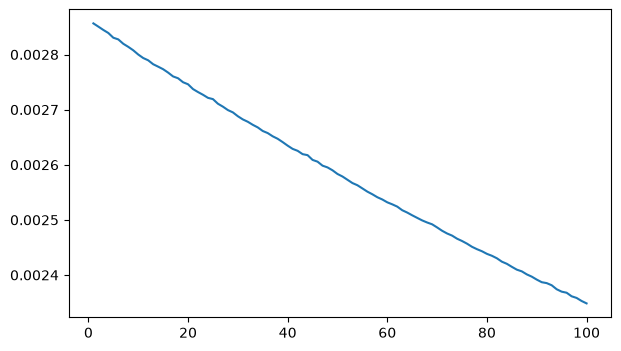

In [56]:
plt.figure(figsize = (7,4))
plt.plot(range(1,epoch+1),loss_history)


#### Step4. 모델 테스트하기

- Sigmoid 출력값에 임계값 0.5를 적용해 클래스를 예측.
- 전체 테스트 데이터 중 정답을 맞힌 개수와 Accuracy(%)를 출력.

In [60]:
model.eval()

correct = 0
total = 0
with torch.no_grad():
    for x_batch, y_batch in test_dl :
        y_hat = model(x_batch)
        pred = (y_hat>=0.5).float()

        correct += (pred == y_batch).sum().item()
        total += y_batch.numel()

accuracy = correct / total * 100
print(f'Accuracy: {accuracy:.2f}%')

Accuracy: 1000.00%


#### Step5. 테스트 결과 시각화

- 실제 클래스와 예측 클래스를 이용해 2×2 혼동행렬(Confusion Matrix)을 작성.
- 실제 클래스별 예측 확률 분포를 히스토그램으로 나타내시오.
- 혼동행렬의 행은 실제 클래스, 열은 예측 클래스로 표시하시오.
- 클래스 0과 클래스 1이 무엇을 의미하는지 그래프에 표시하시오.

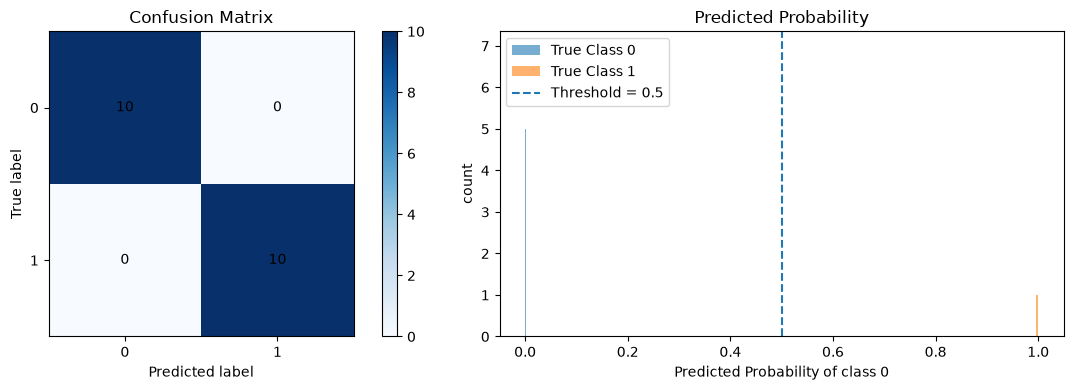

In [61]:
model.eval()

y_true_all = []
y_prob_all = []

with torch.no_grad():
    for x_batch, y_batch in test_dl:
        y_hat = model(x_batch)

        y_true_all.append(y_batch.numpy().reshape(-1))
        y_prob_all.append(y_hat.numpy().reshape(-1))

y_true = np.concatenate(y_true_all).astype(int)
y_prob = np.concatenate(y_prob_all)
y_pred = (y_prob >= 0.5).astype(int)

cm = np.zeros((2,2),dtype=int)

for true,pred in zip(y_true,y_pred):
    cm[true,pred] += 1



fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
axes[0].set_xticks([0,1], labels=['0','1'])
axes[0].set_yticks([0,1], labels=['0','1'])

for i in range(2) :
    for j in range(2) :
        axes[0].text(j, i, cm[i,j], ha='center', va='center')

fig.colorbar(im, ax=axes[0])

# 클래스별 예측 확률 분포
axes[1].hist(y_prob[y_true == 0], bins=20, alpha=0.6, label='True Class 0')
axes[1].hist(y_prob[y_true == 1], bins=20, alpha=0.6, label='True Class 1')
axes[1].axvline(0.5, linestyle='--', label='Threshold = 0.5')
axes[1].set_title('Predicted Probability')
axes[1].set_xlabel('Predicted Probability of class 0')
axes[1].set_ylabel('count')
axes[1].legend()

plt.tight_layout()
plt.show()

#### STEP 6. 파라미터 개수 확인